Easy for trees dataset subset

In [8]:
import multiprocessing
multiprocessing.set_start_method("spawn", force=True)

import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold

# Project root
PROJECT_ROOT = Path.cwd()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [9]:
import sys
from pathlib import Path

# Find project root automatically
PROJECT_ROOT = Path.cwd().parents[1]

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees


In [10]:
from core.metrics import evaluate_tree_new
from evolution.encode_decode import decode
from evolution.genetic_DT_GA import evolve_trees, _load_dataset_csv

In [11]:
def eval_gene_on_dataset(gene, X, y, k=5, seed=123):

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)

    scores = []

    for tr, te in skf.split(X, y):

        algo = decode(gene)
        algo.fit(X[tr], y[tr])

        m = evaluate_tree_new(algo, X[te], y[te])
        scores.append(m["f1"])

    return np.array(scores)

Easy for trees:
Banknote
Iris
Car
TicTacToe
Anneal

Hard for trees:
Balance Scale
Arrhythmia
Heart Disease
Wine Red
Haberman

Interesting intermediate challenging:
Semeion
Sonar
Glass
Cylinder Bands

In [12]:
random.seed(42)

data_path = PROJECT_ROOT / "data"

# (15)
datasets = {
    "anneal": data_path / "anneal.csv",
    "car": data_path / "car.csv",
    "tic_tac_toe": data_path / "tic_tac_toe.csv",
    "iris": data_path / "iris.csv",
    "banknote": data_path / "banknote_authentication.csv",
}

# (5)
unseen_datasets = {
    "haberman": data_path / "haberman.csv",
    "parkinsons": data_path / "parkinsons.csv",
    "breast_cancer": data_path / "breast_cancer.csv",
    "credit_approval": data_path / "credit_approval.csv",
    "ionosphere": data_path / "ionosphere.csv",
}


target_cols = {name: None for name in list(datasets.keys()) + list(unseen_datasets.keys())}

In [13]:
mu = 25
lambd = 25
generations = 30

print("Starting Evolutionary Process...")
print(f"Experiment with mu={mu}, lambda={lambd} for {generations} generations.")
print("Training datasets:", list(datasets.keys()))

Starting Evolutionary Process...
Experiment with mu=25, lambda=25 for 30 generations.
Training datasets: ['anneal', 'car', 'tic_tac_toe', 'iris', 'banknote']


In [7]:
timestamp = time.strftime("%Y%m%d_%H%M")

results_dir = Path(
    r"C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs"
)

results_dir.mkdir(parents=True, exist_ok=True)

print("Figures will be saved in:", results_dir)

Figures will be saved in: C:\Users\sarah\OneDrive\Documentos\DCC_Thesis_codes\AutoML_DecisionTrees\experiments\EvolutionFigs


In [8]:
evo_t0 = time.time()

best_gene, best_fit, history, fitness_rank_history, generalization_history, generalization_sdd_history = evolve_trees(
    datasets,
    unseen_datasets,
    target_cols=target_cols,
    mu=mu,
    lambd=lambd,
    generations=generations)

evo_tf = time.time()


# Tiempo total
total_time = evo_tf - evo_t0
total_minutes = total_time / 60
total_hours = total_time / 3600

# Tiempo promedio por generación
time_per_gen = total_time / generations

print("\n ===== Evolution Summary =====")
print(f"Total time: {total_time:.2f} seconds")
print(f"Total time: {total_minutes:.2f} minutes")
print(f"Total time: {total_hours:.2f} hours")
print(f"Avg time per generation: {time_per_gen:.2f} seconds")

print("\n ===== Results =====")
print("Best gene:", best_gene)
print("Fitness (mean - SDD):", best_fit)


[Evaluation] 25 genes | 5 datasets | 5 folds | workers=18 | timeout=900s

[Progress] 1/25 [OK] gene=[4, 3, 20, 2, 1, 1, 2, 10] fitness=0.8203 mean_f1=0.8842 f1_std=0.0639 total=75.80s pid=28512
  dataset mean F1 | best=0.9652 worst=0.7810 avg=0.8842
  dataset mean F1 values=[0.856, 0.8854, 0.781, 0.9335, 0.9652]
  - anneal               F1 mean=0.8560 best=0.8827 worst=0.7805 folds=[0.8813, 0.7805, 0.8653, 0.8701, 0.8827]
    time total=8.32s decode=0.00s fit=8.17s metrics=0.09s | depth=7.40 nodes=30.60
  - car                  F1 mean=0.8854 best=0.9479 worst=0.8368 folds=[0.8723, 0.8651, 0.8368, 0.9479, 0.9051]
    time total=26.94s decode=0.00s fit=26.79s metrics=0.14s | depth=25.00 nodes=287.80
  - tic_tac_toe          F1 mean=0.7810 best=0.7931 worst=0.7724 folds=[0.7931, 0.7818, 0.7724, 0.7808, 0.7768]
    time total=27.67s decode=0.00s fit=27.53s metrics=0.12s | depth=24.40 nodes=251.00
  - iris                 F1 mean=0.9335 best=0.9666 worst=0.8997 folds=[0.9666, 0.8997, 0.90

In [9]:
# Report generalization across datasets
for name, dataset_path in datasets.items():
    target_col = None if target_cols is None else target_cols.get(name, None)

    X, y = _load_dataset_csv(dataset_path, target_col=target_col)
    scores = eval_gene_on_dataset(best_gene, X, y, k=5)

    print(f"{name}: mean F1={scores.mean():.4f}, std F1={scores.std():.4f}, folds={scores}")

anneal: mean F1=0.9211, std F1=0.0818, folds=[0.78298937 0.87126126 0.98100186 0.97724821 0.99311635]
car: mean F1=0.9451, std F1=0.0318, folds=[0.95188864 0.88421349 0.97009252 0.97117889 0.94789762]
tic_tac_toe: mean F1=0.8719, std F1=0.0241, folds=[0.88537313 0.90077519 0.84164016 0.84477369 0.88703502]
iris: mean F1=0.9269, std F1=0.0386, folds=[0.96658312 0.93324979 0.90150376 0.96658312 0.86666667]
banknote: mean F1=0.9837, std F1=0.0076, folds=[0.977901   0.98529097 0.97402879 0.98522433 0.99630304]


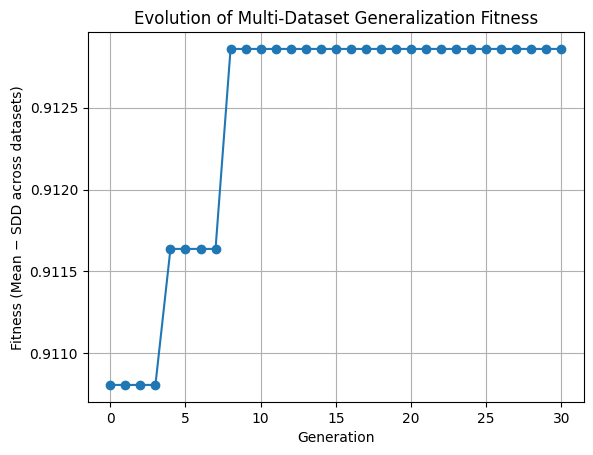

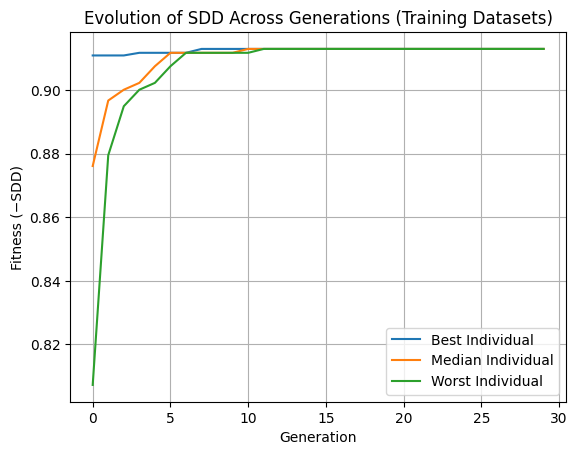

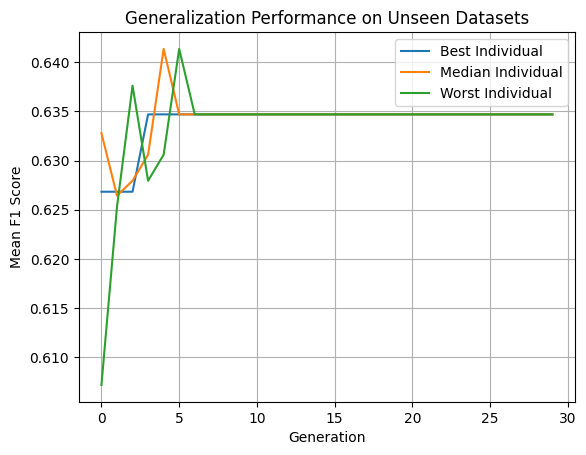

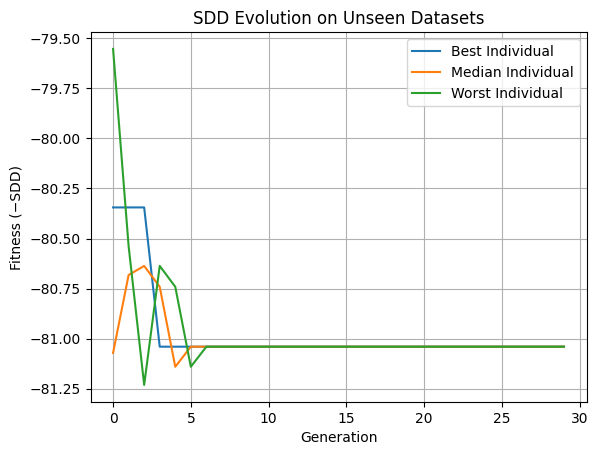

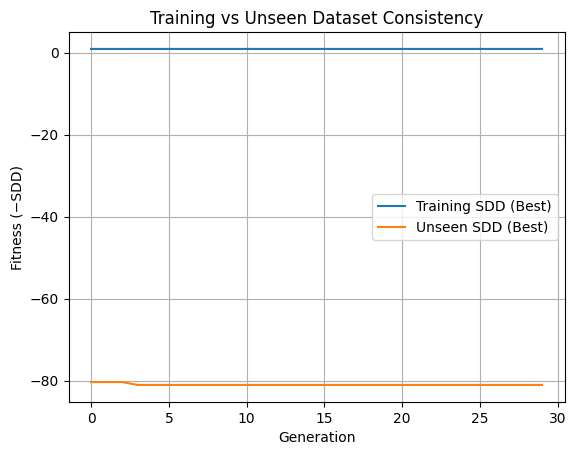

In [10]:
# Graph 1 — Best Fitness Evolution
fig = plt.figure()

plt.plot(history, marker="o")

plt.title("Evolution of Multi-Dataset Generalization Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Mean − SDD across datasets)")
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "fitness_evolution.png", dpi=300)



# Graph 2 — Training SDD Evolution
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Best Individual")
plt.plot(fitness_rank_history["median"], label="Median Individual")
plt.plot(fitness_rank_history["worst"], label="Worst Individual")

plt.title("Evolution of SDD Across Generations (Training Datasets)")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_sdd.png", dpi=300)



# Graph 3 — Generalization F1
fig = plt.figure()

plt.plot(generalization_history["best"], label="Best Individual")
plt.plot(generalization_history["median"], label="Median Individual")
plt.plot(generalization_history["worst"], label="Worst Individual")

plt.title("Generalization Performance on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Mean F1 Score")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "generalization_f1.png", dpi=300)



# Graph 4 — Unseen Dataset SDD
fig = plt.figure()

plt.plot(generalization_sdd_history["best"], label="Best Individual")
plt.plot(generalization_sdd_history["median"], label="Median Individual")
plt.plot(generalization_sdd_history["worst"], label="Worst Individual")

plt.title("SDD Evolution on Unseen Datasets")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)

#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "unseen_sdd.png", dpi=300)



# Graph 5 — Training vs Unseen SDD
fig = plt.figure()

plt.plot(fitness_rank_history["best"], label="Training SDD (Best)")
plt.plot(generalization_sdd_history["best"], label="Unseen SDD (Best)")

plt.title("Training vs Unseen Dataset Consistency")
plt.xlabel("Generation")
plt.ylabel("Fitness (−SDD)")
plt.legend()
plt.grid(True)
#plt.xscale("log")
#plt.yscale("log")

fig.savefig(results_dir / "training_vs_unseen_sdd.png", dpi=300)

plt.show()

In [7]:
import numpy as np
import pandas as pd

from evolution.genetic_DT_GA import (
    _eval_one_algo_all_datasets,
    _fitness_from_dataset_scores,
)

def safe_xi(score, best=1.0, eps=1e-8):
    return abs(score - best) / (((score + best) / 2) + eps)

# ---- Put your winning genomes here ----
WINNING_GENES = {
    "mean_minus_sdd": [4, 3, 1, 3, 1, 1, 3, 9],
    "minus_sdd": [2, 2, 18, 2, 0, 0, 3, 1],
}

k_folds = 5
seed = 42
timeout_s = None

datasets_info = []
for ds_name, ds_path in datasets.items():
    target_col = None if "target_cols" not in globals() else target_cols.get(ds_name, None)
    datasets_info.append((ds_name, str(ds_path), target_col))

dataset_split_seeds = {
    ds_name: abs(hash((seed, ds_name))) % (2**31 - 1)
    for ds_name in datasets.keys()
}

summary_rows = []
detail_rows = []

for exp_name, gene in WINNING_GENES.items():
    print(f"\n===== FINAL EVALUATION: {exp_name} =====")
    print(f"Gene: {gene}")

    out = _eval_one_algo_all_datasets(
        algo_genome=gene,
        datasets_info=datasets_info,
        n_splits=k_folds,
        dataset_split_seeds=dataset_split_seeds,
        bad_score=0.0,
        timeout_s=timeout_s,
    )

    scores_by_dataset = out["results"]

    dataset_mean_f1 = {
        ds: float(np.mean(scores))
        for ds, scores in scores_by_dataset.items()
    }

    dataset_f1_scores = np.array(list(dataset_mean_f1.values()), dtype=float)

    mean_f1 = float(np.mean(dataset_f1_scores))

    # New SDD: percentage differences using best dataset F1 for this genome
    best_dataset_f1 = float(np.max(dataset_f1_scores))

    xi = np.abs(dataset_f1_scores - best_dataset_f1) / (
        (dataset_f1_scores + best_dataset_f1) / 2 + 1e-8
    )

    SDD = float(np.std(xi))
    raw_std_across_datasets = float(np.std(dataset_f1_scores))

    fitness_mean_minus_sdd = mean_f1 - SDD
    fitness_minus_sdd = -SDD

    # Old SDD from the previous -SDD experiment:
    # xi_i = relative difference between dataset mean F1 and ideal best = 1.0
    old_xi_values = np.array([safe_xi(score, best=1.0) for score in dataset_f1_scores], dtype=float)

    if len(old_xi_values) <= 1:
        old_xi_sdd = 0.0
    else:
        old_xi_sdd = float(np.std(old_xi_values, ddof=1))

    old_fitness_minus_sdd = -old_xi_sdd

    print(f"Mean F1: {mean_f1:.6f}")
    print(f"New SDD across datasets: {SDD:.6f}")
    print(f"New Fitness mean - SDD: {fitness_mean_minus_sdd:.6f}")
    print(f"New Fitness -SDD: {fitness_minus_sdd:.6f}")
    print(f"Raw std F1 across datasets: {raw_std_across_datasets:.6f}")
    print(f"Old xi-based SDD: {old_xi_sdd:.6f}")
    print(f"Old Fitness -SDD: {old_fitness_minus_sdd:.6f}")

    summary_rows.append({
        "experiment": exp_name,
        "gene": gene,
        "mean_f1": mean_f1,

        "new_SDD": SDD,
        "new_fitness_mean_minus_SDD": fitness_mean_minus_sdd,
        "new_fitness_minus_SDD": fitness_minus_sdd,

        "raw_std_f1_across_datasets": raw_std_across_datasets,

        "old_xi_based_SDD": old_xi_sdd,
        "old_fitness_minus_SDD": old_fitness_minus_sdd,
        "old_xi_values": old_xi_values.tolist(),

        "infeasible": out["infeasible"],
        "failed_dataset": out["failed_dataset"],
        "failure_reason": out["failure_reason"],
    })

    for ds, scores in scores_by_dataset.items():
        times = out["times"][ds]
        struct = out["structures"][ds]

        mean_ds_f1 = float(np.mean(scores))
        old_ds_xi = safe_xi(mean_ds_f1, best=1.0)

        detail_rows.append({
            "experiment": exp_name,
            "dataset": ds,
            "mean_f1": mean_ds_f1,
            "std_f1_folds": float(np.std(scores)),
            "best_fold_f1": float(np.max(scores)),
            "worst_fold_f1": float(np.min(scores)),
            "old_xi_distance_from_1": old_ds_xi,
            "fold_scores": scores,
            "total_time_s": times["total"],
            "fit_time_s": times["fit"],
            "mean_depth": struct["depth"],
            "mean_nodes": struct["nodes"],
        })

summary_df = pd.DataFrame(summary_rows)
details_df = pd.DataFrame(detail_rows)

display(summary_df)
display(details_df.sort_values(["experiment", "mean_f1"], ascending=[True, False]))


===== FINAL EVALUATION: mean_minus_sdd =====
Gene: [4, 3, 1, 3, 1, 1, 3, 9]
Mean F1: 0.924242
New SDD across datasets: 0.045149
New Fitness mean - SDD: 0.879093
New Fitness -SDD: -0.045149
Raw std F1 across datasets: 0.041408
Old xi-based SDD: 0.050437
Old Fitness -SDD: -0.050437

===== FINAL EVALUATION: minus_sdd =====
Gene: [2, 2, 18, 2, 0, 0, 3, 1]
Mean F1: 0.928011
New SDD across datasets: 0.042356
New Fitness mean - SDD: 0.885656
New Fitness -SDD: -0.042356
Raw std F1 across datasets: 0.038609
Old xi-based SDD: 0.047305
Old Fitness -SDD: -0.047305


,experiment,gene,mean_f1,new_SDD,new_fitness_mean_minus_SDD,new_fitness_minus_SDD,raw_std_f1_across_datasets,old_xi_based_SDD,old_fitness_minus_SDD,old_xi_values,infeasible,failed_dataset,failure_reason
0,mean_minus_sdd,"[4, 3, 1, 3, 1, 1, 3, 9]",0.924242,0.045149,0.879093,-0.045149,0.041408,0.050437,-0.050437,"[0.10406959839137142, 0.06582990220261117, 0.1...",False,None,None
1,minus_sdd,"[2, 2, 18, 2, 0, 0, 3, 1]",0.928011,0.042356,0.885656,-0.042356,0.038609,0.047305,-0.047305,"[0.06123992478184019, 0.05943427926103069, 0.1...",False,None,None


,experiment,dataset,mean_f1,std_f1_folds,best_fold_f1,worst_fold_f1,old_xi_distance_from_1,fold_scores,total_time_s,fit_time_s,mean_depth,mean_nodes
4,mean_minus_sdd,banknote,0.979308,0.007612,0.988909,0.970430,0.020909,"[0.9704301075268817, 0.9852673309761063, 0.970...",8.504846,8.417593,25.0,284.6
3,mean_minus_sdd,iris,0.946409,0.034182,1.000000,0.899471,0.055066,"[0.9665831244778613, 0.8994708994708994, 0.933...",1.359103,1.321875,16.8,55.0
1,mean_minus_sdd,car,0.936268,0.027430,0.979165,0.902727,0.065830,"[0.9142471716047665, 0.9791651731306904, 0.953...",21.890202,21.830642,25.0,644.2
0,mean_minus_sdd,anneal,0.901078,0.106820,1.000000,0.700407,0.104070,"[0.8983471074380166, 1.0, 0.9810018552875694, ...",27.869540,27.818558,11.8,47.8
2,mean_minus_sdd,tic_tac_toe,0.858148,0.054766,0.929688,0.763535,0.152681,"[0.9296875, 0.8435868810910297, 0.878787878787...",51.280691,51.230229,25.0,1109.0
9,minus_sdd,banknote,0.974130,0.010228,0.988941,0.959333,0.026209,"[0.9889411670084851, 0.9778630460448643, 0.959...",7.298909,7.240772,25.0,394.2
6,minus_sdd,car,0.942281,0.025108,0.969573,0.900479,0.059434,"[0.9310553036968132, 0.9695729349020885, 0.965...",15.601209,15.538341,25.0,713.0
5,minus_sdd,anneal,0.940580,0.041098,1.000000,0.898347,0.061240,"[0.8983471074380166, 0.9775706349476841, 0.901...",5.249254,5.200755,16.2,70.2
8,minus_sdd,iris,0.925472,0.040610,0.966583,0.861111,0.077413,"[0.9665831244778613, 0.899749373433584, 0.9333...",1.732400,1.703817,21.0,111.0
7,minus_sdd,tic_tac_toe,0.857595,0.061584,0.929688,0.752000,0.153322,"[0.9296875, 0.8332506203473946, 0.873299186123...",31.294351,31.245814,25.0,1143.8


In [14]:
import numpy as np
import pandas as pd

from evolution.genetic_DT_GA import _eval_one_algo_all_datasets


# ---- Winning genomes ----
WINNING_GENES = {
    "mean_minus_sdd": [4, 3, 1, 3, 1, 1, 3, 9],
    "minus_sdd": [2, 2, 18, 2, 0, 0, 3, 1],
}

k_folds = 5
seed = 42
timeout_s = None


def compute_clean_metrics(scores_by_dataset):
    """
    Computes final report metrics:
    1. Mean F1 across datasets
    2. SDD across datasets, using the old xi-based definition
    3. Raw standard deviation of dataset mean F1
    4. Fitness = Mean(F1) - SDD, where SDD is raw std of F1
       exactly like _fitness_from_dataset_scores
    """

    dataset_mean_f1_values = []

    for scores in scores_by_dataset.values():
        clean_scores = [float(s) for s in scores if np.isfinite(s)]
        mean_f1 = float(np.mean(clean_scores)) if clean_scores else 0.0
        dataset_mean_f1_values.append(mean_f1)

    dataset_mean_f1_values = np.array(dataset_mean_f1_values, dtype=float)

    if len(dataset_mean_f1_values) == 0:
        return -np.inf, np.inf, np.inf, -np.inf, []

    # 1. Mean F1 across datasets
    mean_f1 = float(np.mean(dataset_mean_f1_values))

    # 2. SDD across datasets: old xi-based SDD
    xi_values = np.abs(dataset_mean_f1_values - 1.0) / (
        ((dataset_mean_f1_values + 1.0) / 2) + 1e-8
    )

    sdd_across_datasets = (
        float(np.std(xi_values, ddof=1))
        if len(xi_values) > 1
        else 0.0
    )

    old_fitness_minus_sdd = -sdd_across_datasets

    # 3. Raw standard deviation of F1
    raw_std_f1 = float(np.std(dataset_mean_f1_values))

    # 4. Fitness exactly as in your current function:
    # Mean(F1) - std(dataset_mean_f1_values)
    fitness_mean_f1_minus_std = mean_f1 - raw_std_f1

    return (
        mean_f1,
        old_fitness_minus_sdd,
        raw_std_f1,
        fitness_mean_f1_minus_std,
        dataset_mean_f1_values.tolist(),
    )


datasets_info = []
for ds_name, ds_path in datasets.items():
    target_col = None if "target_cols" not in globals() else target_cols.get(ds_name, None)
    datasets_info.append((ds_name, str(ds_path), target_col))


dataset_split_seeds = {
    ds_name: abs(hash((seed, ds_name))) % (2**31 - 1)
    for ds_name in datasets.keys()
}


summary_rows = []
detail_rows = []


for exp_name, gene in WINNING_GENES.items():
    print(f"\n===== FINAL EVALUATION: {exp_name} =====")
    print(f"Gene: {gene}")

    out = _eval_one_algo_all_datasets(
        algo_genome=gene,
        datasets_info=datasets_info,
        n_splits=k_folds,
        dataset_split_seeds=dataset_split_seeds,
        bad_score=0.0,
        timeout_s=timeout_s,
    )

    scores_by_dataset = out["results"]

    (
        mean_f1,
        old_fitness_minus_sdd,
        raw_std_f1,
        fitness_mean_f1_minus_sdd,
        dataset_mean_f1_values,
    ) = compute_clean_metrics(scores_by_dataset)

    print(f"Mean F1 across datasets: {mean_f1:.6f}")
    print(f"SDD across datasets / Old Fitness -SDD: {old_fitness_minus_sdd:.6f}")
    print(f"Raw standard deviation of F1: {raw_std_f1:.6f}")
    print(f"Fitness Mean(F1) - SDD: {fitness_mean_f1_minus_sdd:.6f}")

    summary_rows.append({
        "experiment": exp_name,
        "gene": gene,
        "mean_f1_across_datasets": mean_f1,
        "old_fitness_minus_sdd": old_fitness_minus_sdd,
        "raw_std_f1_across_datasets": raw_std_f1,
        "fitness_mean_f1_minus_sdd": fitness_mean_f1_minus_sdd,
        "dataset_mean_f1_values": dataset_mean_f1_values,
        "infeasible": out["infeasible"],
        "failed_dataset": out["failed_dataset"],
        "failure_reason": out["failure_reason"],
    })

    for ds, scores in scores_by_dataset.items():
        clean_scores = [float(s) for s in scores if np.isfinite(s)]

        detail_rows.append({
            "experiment": exp_name,
            "dataset": ds,
            "mean_f1": float(np.mean(clean_scores)) if clean_scores else 0.0,
            "std_f1_folds": float(np.std(clean_scores)) if clean_scores else 0.0,
            "fold_scores": clean_scores,
        })


summary_df = pd.DataFrame(summary_rows)
details_df = pd.DataFrame(detail_rows)

display(summary_df)
display(details_df.sort_values(
    ["experiment", "mean_f1"],
    ascending=[True, False]
))


===== FINAL EVALUATION: mean_minus_sdd =====
Gene: [4, 3, 1, 3, 1, 1, 3, 9]
Mean F1 across datasets: 0.924242
SDD across datasets / Old Fitness -SDD: -0.050437
Raw standard deviation of F1: 0.041408
Fitness Mean(F1) - SDD: 0.882834

===== FINAL EVALUATION: minus_sdd =====
Gene: [2, 2, 18, 2, 0, 0, 3, 1]
Mean F1 across datasets: 0.928011
SDD across datasets / Old Fitness -SDD: -0.047305
Raw standard deviation of F1: 0.038609
Fitness Mean(F1) - SDD: 0.889402


,experiment,gene,mean_f1_across_datasets,old_fitness_minus_sdd,raw_std_f1_across_datasets,fitness_mean_f1_minus_sdd,dataset_mean_f1_values,infeasible,failed_dataset,failure_reason
0,mean_minus_sdd,"[4, 3, 1, 3, 1, 1, 3, 9]",0.924242,-0.050437,0.041408,0.882834,"[0.9010777975104702, 0.9362678381306015, 0.858...",False,None,None
1,minus_sdd,"[2, 2, 18, 2, 0, 0, 3, 1]",0.928011,-0.047305,0.038609,0.889402,"[0.9405795272467168, 0.9422809647737826, 0.857...",False,None,None


,experiment,dataset,mean_f1,std_f1_folds,fold_scores
4,mean_minus_sdd,banknote,0.979308,0.007612,"[0.9704301075268817, 0.9852673309761063, 0.970..."
3,mean_minus_sdd,iris,0.946409,0.034182,"[0.9665831244778613, 0.8994708994708994, 0.933..."
1,mean_minus_sdd,car,0.936268,0.027430,"[0.9142471716047665, 0.9791651731306904, 0.953..."
0,mean_minus_sdd,anneal,0.901078,0.106820,"[0.8983471074380166, 1.0, 0.9810018552875694, ..."
2,mean_minus_sdd,tic_tac_toe,0.858148,0.054766,"[0.9296875, 0.8435868810910297, 0.878787878787..."
9,minus_sdd,banknote,0.974130,0.010228,"[0.9889411670084851, 0.9778630460448643, 0.959..."
6,minus_sdd,car,0.942281,0.025108,"[0.9310553036968132, 0.9695729349020885, 0.965..."
5,minus_sdd,anneal,0.940580,0.041098,"[0.8983471074380166, 0.9775706349476841, 0.901..."
8,minus_sdd,iris,0.925472,0.040610,"[0.9665831244778613, 0.899749373433584, 0.9333..."
7,minus_sdd,tic_tac_toe,0.857595,0.061584,"[0.9296875, 0.8332506203473946, 0.873299186123..."
